In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from smodels.experiment.databaseObj import Database
from smodels.base.physicsUnits import GeV, pb
from smodels.experiment.expAuxiliaryFuncs import rescaleWidth

In [4]:
# Configuration
width_fraction = 0.0099
mass_range = (2000, 5000)
source_step = 20.0
cross_section_range_fb = (1e-4, 1e2)
output_dir = Path('../paper_plots')
output_dir.mkdir(parents=True, exist_ok=True)

colors = plt.cm.tab20.colors
analyses = {
    'CMS-EXO-19-012': dict(txname='TRV1jj', channel='dijet', color=colors[8], ls='-'),
    'ATLAS-EXOT-2019-03': dict(txname='TRV1jj', channel='dijet', color=colors[6], ls='-'),
    'ATLAS-EXOT-2018-48': dict(txname='TRV1tt', channel=r'$t\bar t$', color=colors[2], ls='-'),
}
benchmark = {
    'mass_GeV': 3000.0,
    'sigma_tt_pb': 0.00013259*9.978330e-01, #sigma_pp2Z' * BR(Z'->ttbar)
    'sigma_jj_pb': 0.00013259*2*1.083506e-03 #sigma_pp2Z' * BR(Z'->qqbar)
}

plt.rcParams.update({'savefig.dpi': 300, 'text.usetex': True,
                     'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica']})
sns.set_style('ticks', {'font.family': 'Times New Roman', 'font.serif': 'Times New Roman'})
sns.set_context('paper', font_scale=1.8)

## Extract the observed upper-limit curves

In [5]:
db = Database('official')
results = db.getExpResults(analysisIDs=list(analyses), dataTypes=['upperLimit'])
masses = np.arange(mass_range[0], mass_range[1] + source_step/2, source_step)

def upper_limit_pb(tx, mass_gev):
    # SModelS getULFor(sms=None, mass=...) expects the *transformed flat grid*.
    # In particular, totalwidth must be logarithmically rescaled.
    point = []
    for index in sorted(tx.dataMap):
        _, attribute, unit = tx.dataMap[index]
        if attribute not in ('mass', 'totalwidth'):
            raise ValueError(f'Unsupported database coordinate: {attribute}')
        value = (mass_gev if attribute == 'mass' else mass_gev*width_fraction)*GeV
        value = value.asNumber(unit)
        point.append(rescaleWidth(value) if attribute == 'totalwidth' else value)
    ul = tx.getULFor(sms=None, mass=point)
    return np.nan if ul is None else ul.asNumber(pb)

rows = []
for analysis, config in analyses.items():
    matches = [tx for exp in results if exp.globalInfo.id == analysis
               for tx in exp.getTxNames() if tx.txName == config['txname']]
    if len(matches) != 1:
        raise ValueError(f'{analysis}/{config["txname"]}: found {len(matches)} maps instead of one')
    tx = matches[0]
    print(f'{analysis}: {config["txname"]}, dataMap={tx.dataMap}')
    for mass in masses:
        rows.append((analysis, mass, upper_limit_pb(tx, mass)))

limits = pd.DataFrame(rows, columns=['analysis', 'mass_gev', 'ul_pb'])
for analysis in analyses:
    valid = limits.loc[(limits.analysis == analysis) & limits.ul_pb.gt(0)]
    print(f'{analysis}: {len(valid)}/{len(masses)} available mass points')
if not np.isfinite(limits.ul_pb).any():
    raise RuntimeError('The database returned no valid upper limits. Check the maps and width.')

CMS-EXO-19-012: TRV1jj, dataMap={0: (1, 'mass', 1.00E+00 [GeV]), 1: (1, 'totalwidth', 1.00E+00 [GeV])}
ATLAS-EXOT-2019-03: TRV1jj, dataMap={0: (1, 'mass', 1.00E+00 [GeV]), 1: (1, 'totalwidth', 1.00E+00 [GeV])}
ATLAS-EXOT-2018-48: TRV1tt, dataMap={0: (1, 'mass', 1.00E+00 [GeV]), 1: (1, 'totalwidth', 1.00E+00 [GeV])}
CMS-EXO-19-012: 151/151 available mass points
ATLAS-EXOT-2019-03: 76/151 available mass points
ATLAS-EXOT-2018-48: 151/151 available mass points


## Plot helpers

In [6]:
def plot_limits(ax, selected, unit='fb'):
    if isinstance(selected, (list, tuple)):
        selected = {analysis: analyses[analysis] for analysis in selected}

    if unit not in ('fb', 'pb'):
        raise ValueError("unit must be 'fb' or 'pb'")

    factor = 1e3 if unit == 'fb' else 1.0
    upper_range = cross_section_range_fb[1] if unit == 'fb' else cross_section_range_fb[1] / 1e3

    for analysis, config in selected.items():
        curve = limits.loc[limits.analysis == analysis].sort_values('mass_gev')

        x = curve.mass_gev.to_numpy()
        y = curve.ul_pb.to_numpy(dtype=float, copy=True) * factor

        valid = np.isfinite(y) & (y > 0)
        y = np.where(valid, y, np.nan)

        ax.plot(x, y, lw=2.2, color=config['color'], ls=config['ls'],
                label=f'{analysis} ({config["channel"]})')

        ax.fill_between(x, y, upper_range, where=valid,
                        color=config['color'], alpha=0.15)


def add_benchmark(ax, signal, color='black', unit='fb'):
    if signal == 'jj':
        sigma = benchmark['sigma_jj_pb']
        #label = r'$\sigma(pp\to Z^\prime\to q\bar q)$'
        label = 'Benchmark'
    elif signal == 'tt':
        sigma = benchmark['sigma_tt_pb']
        #label = r'$\sigma(pp\to Z^\prime\to t\bar t)$'
        label = 'Benchmark'
    else:
        raise ValueError("signal must be 'jj' or 'tt'")

    factor = 1e3 if unit == 'fb' else 1.0
    sigma *= factor

    ax.scatter(benchmark['mass_GeV'], sigma, s=95, marker='o',
               color=color, zorder=5, label=label)



## Dijet limits and dijet benchmark

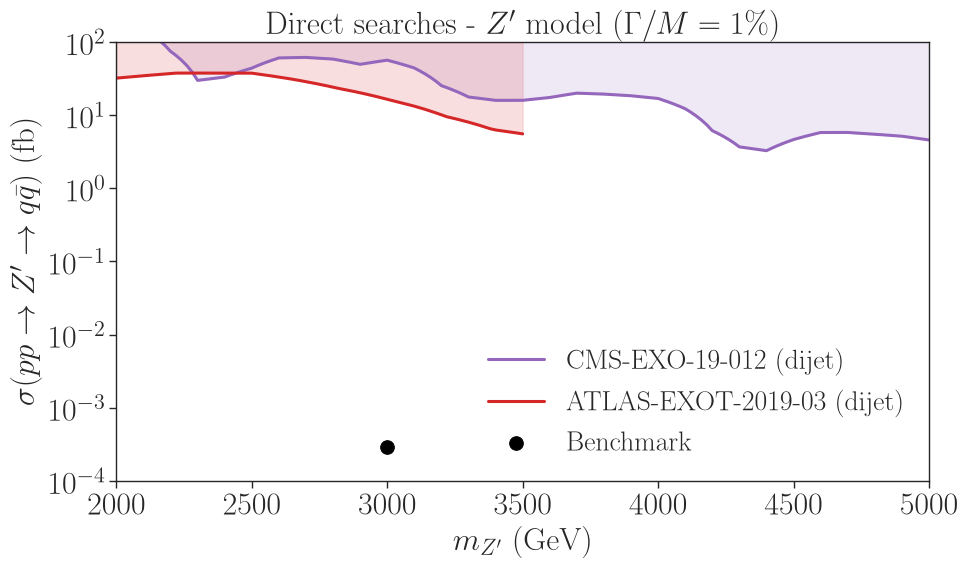

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_limits(ax, ['CMS-EXO-19-012', 'ATLAS-EXOT-2019-03'])
ax.set_ylabel(r'$\sigma(pp\to Z^\prime\to q\bar q)$ (fb)', fontsize=23)
ax.set_xlabel(r'$m_{Z^\prime}$ (GeV)', fontsize=23)
ax.set_title(r"Direct searches - $Z'$ model ($\Gamma/M=1\%$)", fontsize=23)
add_benchmark(ax, 'jj')
ax.set_yscale('log')
ax.set_xlim(*mass_range)
ax.set_ylim(*cross_section_range_fb)
ax.set_yticks([1e-4,1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2])
ax.tick_params(axis='both', labelsize=23)
ax.legend(loc='lower right', framealpha=0, fontsize=20)
fig.tight_layout()
fig.savefig(output_dir/'directSearches_Zprime_qq.png', bbox_inches='tight')
plt.show()

## $t\bar t$ limit and $t\bar t$ benchmark

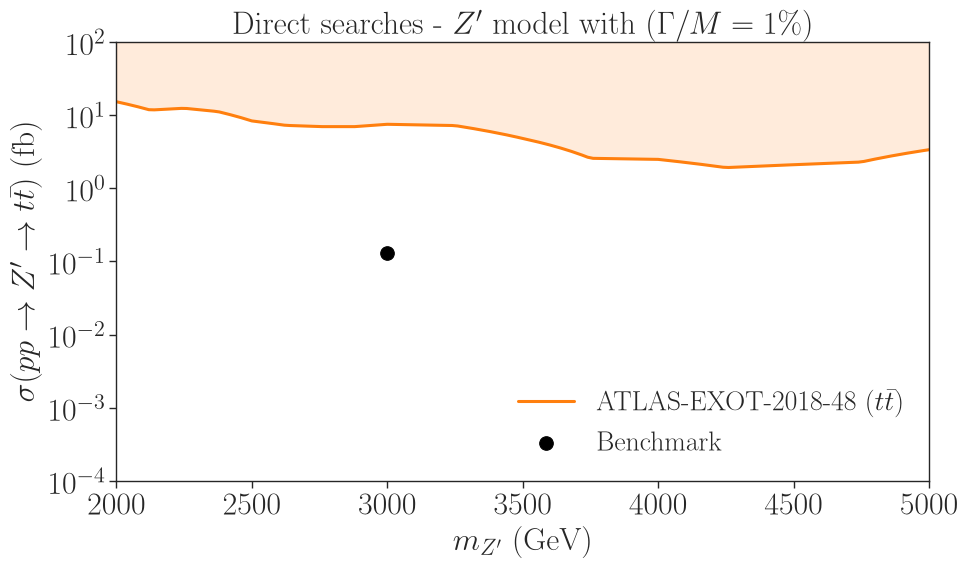

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_limits(ax, ['ATLAS-EXOT-2018-48'])
ax.set_ylabel(r'$\sigma(pp\to Z^\prime\to t\bar t)$ (fb)', fontsize=23)
ax.set_xlabel(r'$m_{Z^\prime}$ (GeV)', fontsize=23)
ax.set_yscale('log')
ax.set_xlim(*mass_range)
ax.set_ylim(*cross_section_range_fb)
ax.set_yticks([1e-4,1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2])
ax.tick_params(axis='both', labelsize=23)
add_benchmark(ax, 'tt')
ax.legend(loc='lower right', framealpha=0, fontsize=20)
ax.set_title(r"Direct searches - $Z'$ model with ($\Gamma/M=1\%$)", fontsize=23)
fig.tight_layout()
fig.savefig(output_dir/'directSearches_Zprime_tt.png', bbox_inches='tight')
plt.show()

# Broad $Z^\prime$ constraint

UL at 3000 GeV: 107.302500 fb
Reference database entry: 107.302500 fb


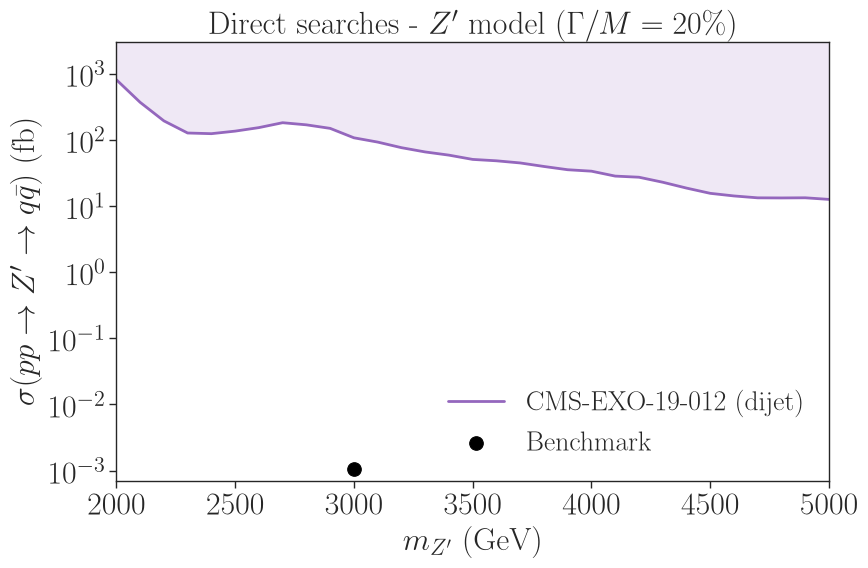

In [14]:

import numpy as np
import matplotlib.pyplot as plt

from smodels.experiment.databaseObj import Database
from smodels.experiment.expAuxiliaryFuncs import unscaleWidth
from smodels.base.physicsUnits import fb

broad_benchmark_xsec = 0.0011321*2*4.629702e-04 * 1e3  # Convert from pb to fb

# Load the experimental analysis
db = Database("official")
exp = db.getExpResults(analysisIDs=["CMS-EXO-19-012"])[0]

tx = next(
    tx for ds in exp.datasets for tx in ds.txnameList
    if tx.txName == "TRV1jj"
)

# Extract the original database grid without interpolation
data = tx.txnameData
points = np.array([
    data.inversePCAtransf(p) for p in data.tri.points
], dtype=float)

mass_grid = points[:, 0]
width_grid = np.array([unscaleWidth(w) for w in points[:, 1]])
ul_grid = np.array([(v * tx.y_unit).asNumber(fb) for v in data.y_values])

# Select Gamma/M = 20%
BROAD_WIDTH_FRACTION = 0.20  # Independent of the narrow scan
mask = np.isclose(width_grid / mass_grid, BROAD_WIDTH_FRACTION, rtol=1e-7)

broad_masses = mass_grid[mask]
broad_limits = ul_grid[mask]

# Sort by mass
order = np.argsort(broad_masses)
broad_masses, broad_limits = broad_masses[order], broad_limits[order]


# Diagnostic at 3 TeV
idx = np.where(np.isclose(broad_masses, 3000))[0]
if len(idx):
    print(f"UL at 3000 GeV: {broad_limits[idx[0]]:.6f} fb")
    print("Reference database entry: 107.302500 fb")

# Plot
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(broad_masses, broad_limits,
        lw=2, ms=3.5, color=colors[8],
        label=r"CMS-EXO-19-012 (dijet)")
ax.fill_between(broad_masses, broad_limits, 1e4,
                color=colors[8], alpha=0.15)
ax.scatter(3000, broad_benchmark_xsec, s=95, marker='o', color ='black', label = 'Benchmark')

ax.set_yscale("log")
ax.set_xlabel(r"$m_{Z'}$ (GeV)", fontsize=23)
ax.set_ylabel(r"$\sigma(p p \to Z' \to q\bar q)$ (fb)", fontsize=23)
ax.set_title(r"Direct searches - $Z'$ model ($\Gamma/M=20\%$)", fontsize=23)
ax.tick_params(axis='both', labelsize=23)
ax.set_yticks([1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3])
ax.set_ylim(7e-4, 3e3)
ax.set_xlim(2000, 5000)
ax.legend(loc='lower right', framealpha=0, fontsize=20)
plt.tight_layout()
fig.savefig(output_dir/'directSearches_Zprime_broad_qq.png', bbox_inches='tight')
plt.show()



In [17]:
print(0.0011321*2*4.629702e-04*1e3)
print(0.0011321*9.990741e-01 *1e3)

0.0010482571268400002
1.13105178861
